# Mammalian cell cycle, growth signaling and apoptosis (Sizek et al.)

This notebook presents the stochastic simulations of the model of
[Sizek et al. (PLoS Comput Biol, 2019)](https://doi.org/10.1371/journal.pcbi.1006402), on the
[MaBoSS website](https://maboss.curie.fr). The model, with 87 nodes, integrates growth signaling, the regulatory
network controlling the mammalian cell cycle, and apoptosis.

The simulations are adapted from the tutorial of the CoLoMoTo software suite
([Noël et al., Interface Focus, 2025](https://doi.org/10.1098/rsfs.2025.0002)). The
[complete tutorial notebook](https://github.com/colomoto/colomoto-tutorial-sizek) also covers the analysis of
this model with other tools (GINsim, bioLQM, BNS...).

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/) with an executable of MaBoSS supporting more than
64 nodes (such as `MaBoSS_128n`) and [pygraphviz](https://pygraphviz.github.io/), all provided by the conda package
(`conda install -c colomoto pymaboss`), and the files
`CellCycleControl_Sizek_PCB_2019.bnd` and `CellCycleControl_Sizek_PCB_2019.cfg`, in the same folder as this
notebook. These files were obtained by converting the
[model of the GINsim repository](https://ginsim.github.io/models/2019-mammal-cell-cycle-control/) with bioLQM.

In [1]:
import math
import os
import maboss
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import HPacker

# The figures are saved in the "figures" folder
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "figure.constrained_layout.use": True})

def legend_below():
    """Move the legend of the current figure below the plot, in centered rows of similar widths."""
    figure, legend = plt.gcf(), plt.gca().get_legend()
    handles, labels = legend.legend_handles, [text.get_text() for text in legend.get_texts()]
    legend.remove()
    legend = figure.legend(handles, labels, loc="outside lower center", ncols=1)
    # Matplotlib fills the rows from the left: we rearrange the entries of the legend in centered rows,
    # as few as possible within the width of the plot, and of similar widths
    column = legend._legend_handle_box.get_children()[0]
    entries, column.align = column.get_children(), "center"
    sep = legend.columnspacing * legend.prop.get_size_in_points() * figure.dpi / 72
    widths = [entry.get_bbox(figure.canvas.get_renderer()).width + sep for entry in entries]
    max_width = 0.8 * figure.get_figwidth() * figure.dpi
    for n_rows in range(math.ceil(sum(widths) / max_width), len(entries) + 1):
        rows, row_widths = [[]], [0]
        for entry, width in zip(entries, widths):
            if rows[-1] and row_widths[-1] + width / 2 > sum(widths) / n_rows:
                rows.append([])
                row_widths.append(0)
            rows[-1].append(entry)
            row_widths[-1] += width
        if max(row_widths) <= max_width:
            break
    column._children = [HPacker(sep=sep, align="baseline", children=row) for row in rows]

## The model

The model was exported from GINsim with all the initial values set to 0. We set the simulation parameters used in
the tutorial: 5000 trajectories, up to time 200, with a time window of 0.5. For reproducibility, we use the
pseudo-random generator, and 4 threads.

In [2]:
model = maboss.load("CellCycleControl_Sizek_PCB_2019.bnd", "CellCycleControl_Sizek_PCB_2019.cfg")
model.update_parameters(sample_count=5000, max_time=200, time_tick=0.5, use_physrandgen=0, thread_count=4)
print(len(model.network), "nodes")

87 nodes


We select the output nodes, i.e. the nodes reported in the results, and set the initial state defined by Sizek
et al. in their figure 6.

In [3]:
init_active = ["AKT_B", "BCL2", "BCLXL", "Cdc20", "Cdc25A", "Cdc25B", "Cdc25C", "Cdh1", "CyclinA_mRNA", "CyclinD1",
               "E2F1", "ERK", "Emi1", "GF", "GF_High", "Grb2", "IAPs", "MCL_1", "MEK", "Myc", "ORC", "PDK1", "PI3K",
               "PIP3", "Plk1_H", "RAF", "RTK", "Ras", "S6K", "SOS", "TSC2", "UbcH10", "eIF4E", "f4N_DNA", "mTORC1",
               "mTORC2", "pAPC"]

WT = model.copy()
WT.network.set_output(("CyclinB", "Casp3", "PI3K_H", "E2F1", "Replication", "p21", "RTK"))
maboss.set_nodes_istate(WT, init_active, [0, 1])

## Wild type

The simulations reveal a transient cyclic-like behaviour, which is eventually lost due to the spontaneous
activation of Casp3, revealing the progressive dominance of the apoptotic stable state.

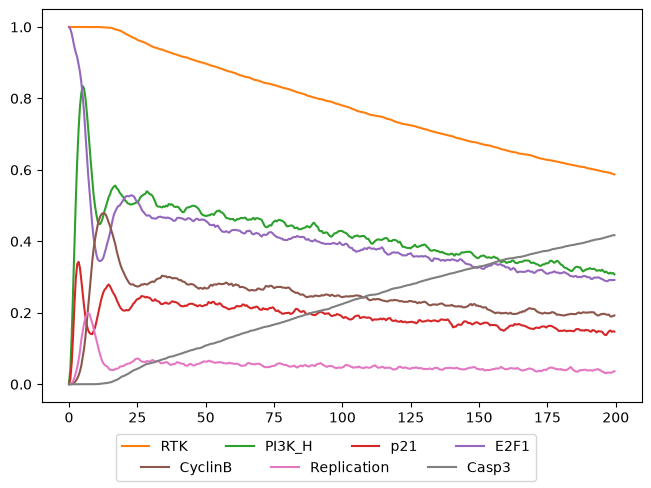

In [4]:
result_WT = WT.run()
result_WT.plot_node_trajectory()
legend_below()
plt.savefig("figures/sizek_wt_nodes.png")

The entropy first rises abruptly, then slowly decreases, while the transition entropy shows a small peak before
remaining close to zero: this suggests a transient periodic behaviour, which collapses as more and more cells
trigger apoptosis.

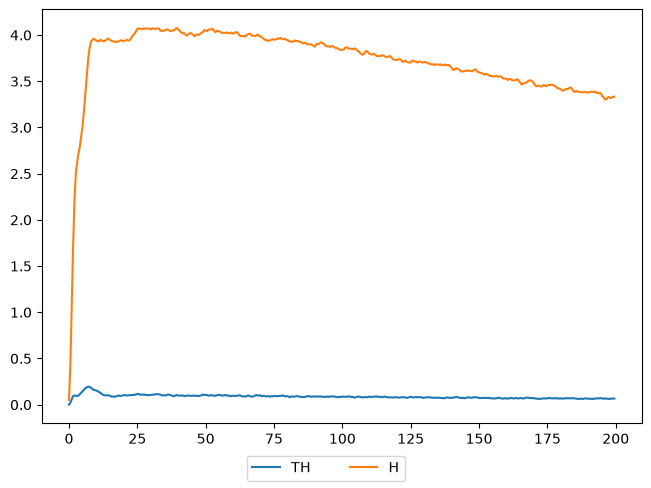

In [5]:
result_WT.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/sizek_wt_entropies.png")

The final states (the states below 3% are grouped as "Others"):

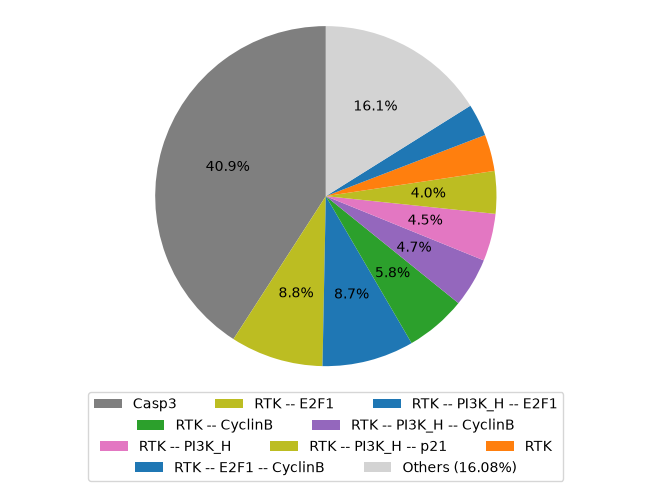

In [6]:
result_WT.plot_piechart(prob_cutoff=0.03)
legend_below()
plt.savefig("figures/sizek_wt_final_states.png")

## Death signal

TRAIL is a ligand binding to death receptors and initiating the death pathways. With TRAIL active at the initial
state, Casp3, and thus apoptosis, rise much faster. The entropy drops faster, and the transition entropy stays
around zero, suggesting a stable state.

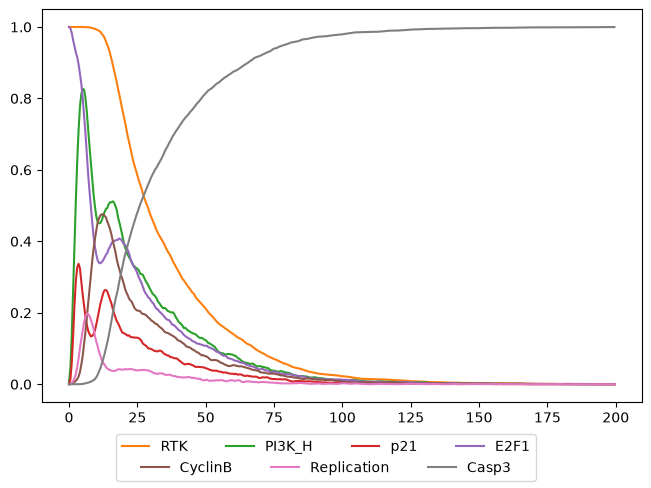

In [7]:
WT_death = WT.copy()
maboss.set_nodes_istate(WT_death, ["Trail"] + init_active, [0, 1])
result_death = WT_death.run()
result_death.plot_node_trajectory()
legend_below()
plt.savefig("figures/sizek_trail_nodes.png")

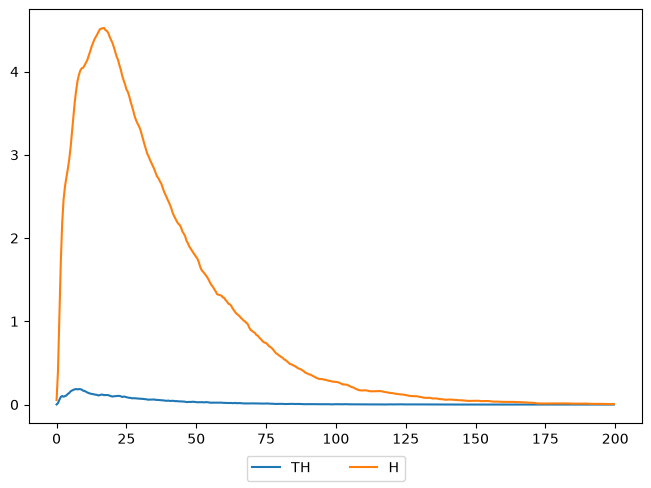

In [8]:
result_death.plot_entropy_trajectory()
legend_below()
plt.savefig("figures/sizek_trail_entropies.png")

## Casp8 mutants

Casp8 is a caspase initiating the apoptotic cascade. Its ectopic activity drives the cells into apoptosis faster.
On the contrary, when Casp8 is knocked down, Casp3 is ultimately activated, as in the wild type: in this model,
apoptosis can occur even without Casp8. To compare the three simulations, we plot the probability of Casp3 with
pandas.

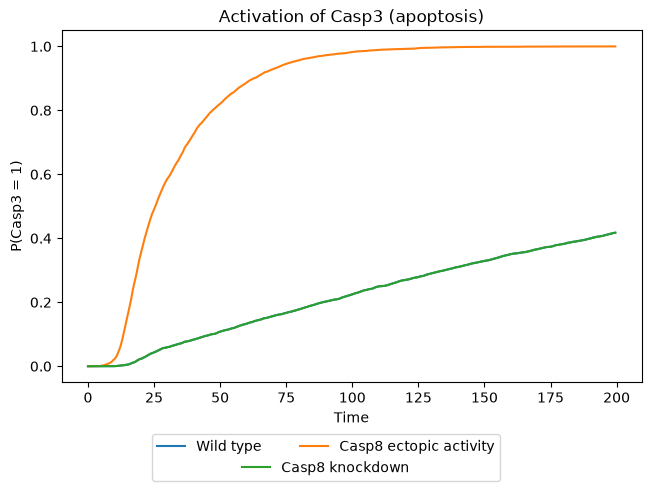

In [9]:
casp8_on = WT.copy()
casp8_on.mutate("Casp8", "ON")
casp8_off = WT.copy()
casp8_off.mutate("Casp8", "OFF")

casp3 = pd.DataFrame({
    "Wild type": result_WT.get_nodes_probtraj()["Casp3"],
    "Casp8 ectopic activity": casp8_on.run().get_nodes_probtraj()["Casp3"],
    "Casp8 knockdown": casp8_off.run().get_nodes_probtraj()["Casp3"],
})
casp3.plot(title="Activation of Casp3 (apoptosis)", xlabel="Time", ylabel="P(Casp3 = 1)")
legend_below()
plt.savefig("figures/sizek_casp8.png")

## Screening of mutants

We simulate the loss-of-function and the ectopic activation of five nodes, and look for the mutants blocking
apoptosis (Casp3 activity below 1%) while keeping the cell cycle active (CyclinE activity above 15%): such
mutants correspond to a highly proliferative phenotype.

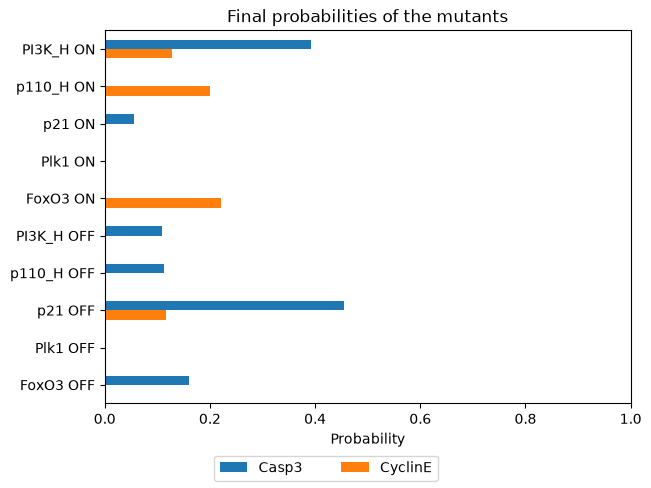

In [10]:
from maboss.pipelines import simulate_single_mutants, filter_sensitivity

explore = WT.copy()
explore.network.set_output(["Casp3", "CyclinA", "CyclinB", "CyclinE"])
mutants = simulate_single_mutants(explore, ["PI3K_H", "p110_H", "p21", "Plk1", "FoxO3"], sign="BOTH")

final = pd.DataFrame({f"{node} {sign}": result.get_last_nodes_probtraj().iloc[0]
                      for (node, sign), result in mutants.items()})
final.T.fillna(0)[["Casp3", "CyclinE"]].plot.barh(title="Final probabilities of the mutants", xlim=(0, 1))
plt.xlabel("Probability")
plt.gca().invert_yaxis()
legend_below()
plt.savefig("figures/sizek_mutants.png")

In [11]:
selected = filter_sensitivity(mutants, node="Casp3", maximum=0.01)
selected = filter_sensitivity(selected, node="CyclinE", minimum=0.15)
print("Mutants blocking apoptosis while keeping the cell cycle:",
      ", ".join(f"{node} {sign}" for node, sign in selected))

Mutants blocking apoptosis while keeping the cell cycle: p110_H ON, FoxO3 ON


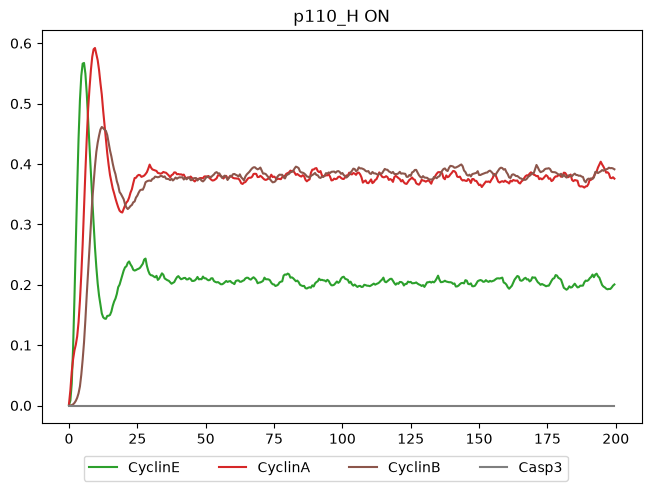

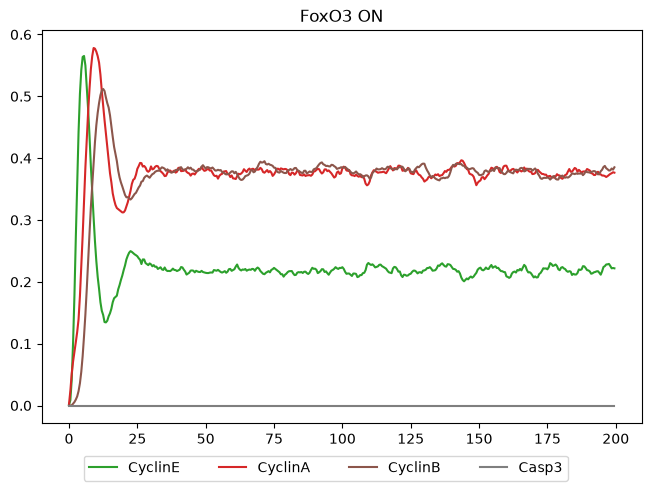

In [12]:
for (node, sign), result in selected.items():
    result.plot_node_trajectory()
    plt.title(f"{node} {sign}")
    legend_below()
    plt.savefig(f"figures/sizek_mutant_{node}_{sign}.png")

Both the sustained activations of p110 and FoxO3 turn off Casp3, while maintaining the cell cycle.

## Order of activation of the cyclins

In the wild type, the cyclins should be activated in the following order: CyclinE, then CyclinA, then CyclinB,
and inactivated in the same order. The probabilities show the expected sequence of peaks; as MaBoSS reports
mean probabilities over many trajectories, these oscillations are rapidly damped.

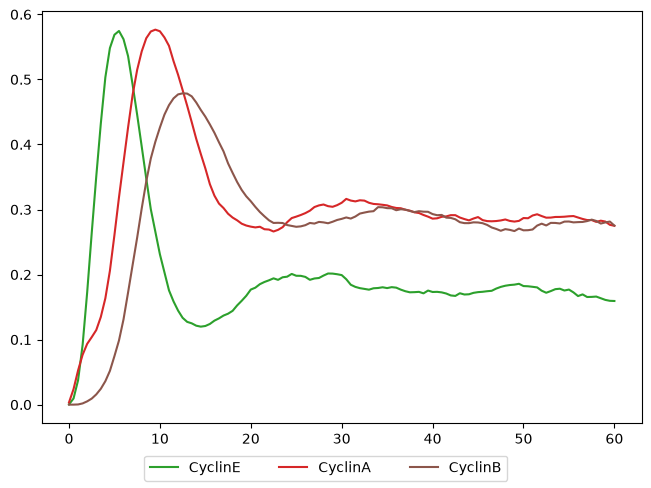

In [13]:
cyclins = ["CyclinE", "CyclinA", "CyclinB"]
WT_cyclins = WT.copy()
WT_cyclins.network.set_output(cyclins)
WT_cyclins.network.set_observed_graph_nodes(cyclins)
result_cyclins = WT_cyclins.run()
result_cyclins.plot_node_trajectory(until=60)
legend_below()
plt.savefig("figures/sizek_cyclins.png")

MaBoSS can also estimate the frequencies of the transitions between the activity patterns of selected nodes,
over all the individual trajectories, and plot them as a *compressed state transition graph*: the darker the
arrow, the more probable the transition.

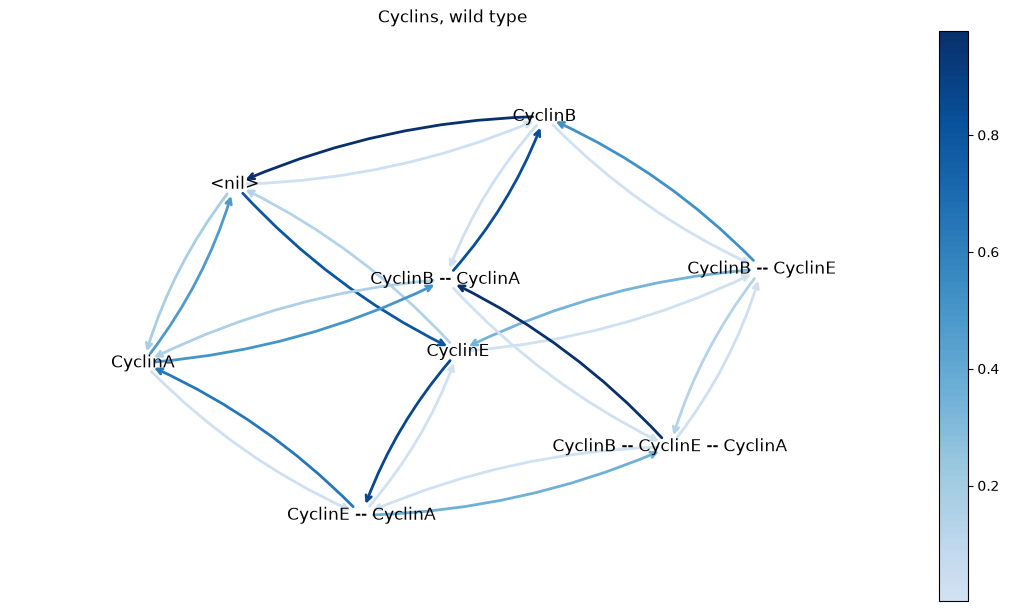

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
result_cyclins.plot_observed_graph(axes=ax)
ax.set_title("Cyclins, wild type")
ax.margins(0.15)
plt.savefig("figures/sizek_cyclins_graph.png")

Starting from the state without active cyclin (G0), the most probable sequence of transitions successively involves
the activation of CyclinE, the activation of CyclinA, the inactivation of CyclinE, the activation of CyclinB,
the inactivation of CyclinA, and finally the inactivation of CyclinB, completing the cycle. Other cycles are
followed with lower probabilities.

## Timing of apoptosis along the cell cycle

We add Casp3 to the observed nodes, to see at which point of the cell cycle apoptosis is triggered, in the wild
type and when p110 is constantly active. The transitions with a probability below 2% are not shown.

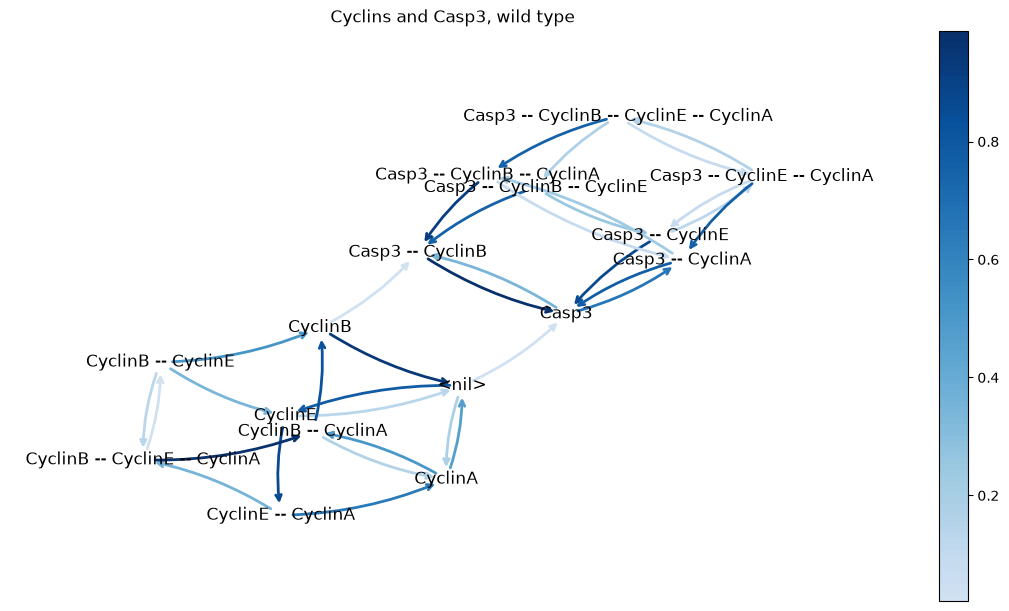

In [15]:
nodes = ["Casp3"] + cyclins
WT_casp3 = WT.copy()
WT_casp3.network.set_output(nodes)
WT_casp3.network.set_observed_graph_nodes(nodes)

fig, ax = plt.subplots(figsize=(10, 6))
WT_casp3.run().plot_observed_graph(axes=ax, prob_cutoff=0.02)
ax.set_title("Cyclins and Casp3, wild type")
ax.margins(0.15)
plt.savefig("figures/sizek_casp3_graph.png")

There are two main ways to activate apoptosis: from the state without active cyclin, which presumably represents
G0, and from the state where only CyclinB is active, which tentatively represents the G2/M phase.

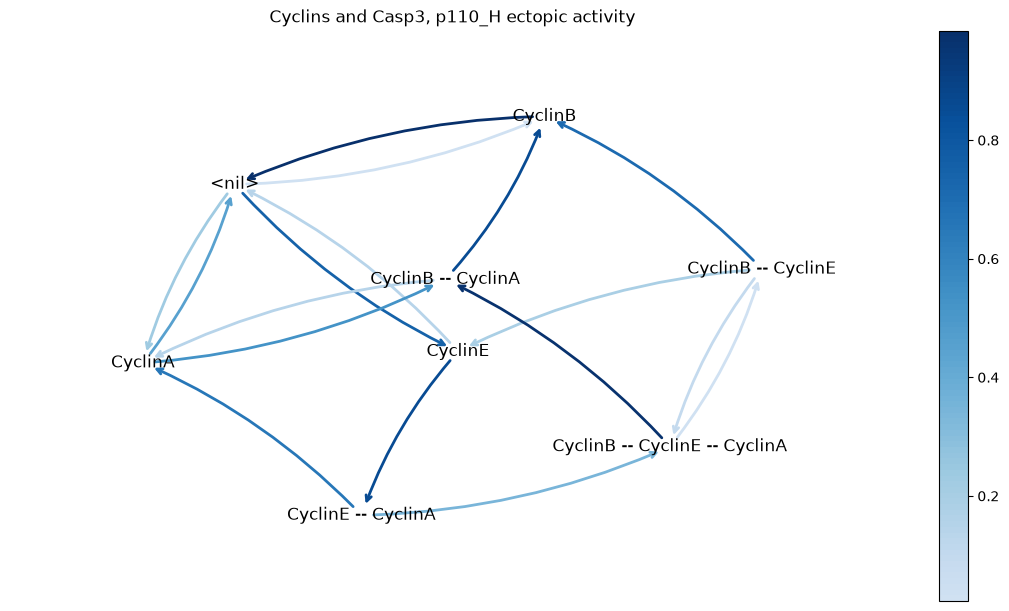

In [16]:
p110 = WT_casp3.copy()
p110.mutate("p110_H", "ON")

fig, ax = plt.subplots(figsize=(10, 6))
p110.run().plot_observed_graph(axes=ax, prob_cutoff=0.02)
ax.set_title("Cyclins and Casp3, p110_H ectopic activity")
ax.margins(0.15)
plt.savefig("figures/sizek_p110_graph.png")

The ectopic activity of p110_H completely disables the activation of apoptosis, and maintains the oscillatory
behaviour.